# Machine Learning Model Performance Evaluation
## Real-world dataset: Mauna Loa Weekly Atmospheric CO₂ (1958–2001)

**Objective:** evaluate machine-learning models using classification and regression metrics, with tables and plots.

### Why this dataset?
This notebook uses a real, public-domain series of weekly atmospheric carbon-dioxide measurements from Mauna Loa Observatory, Hawaii. The packaged source records measurements from March 1958 to December 2001. The CSV provided with this notebook contains the measured observations; blank values are original missing readings, not generated rows.

**Dataset source and citation:** statsmodels, *Mauna Loa Weekly Atmospheric CO2 Data*, based on Keeling and Whorf (2004):
https://www.statsmodels.org/stable/datasets/generated/co2.html

### How the requested metrics are covered
The assignment mixes classification metrics with regression metrics, so the notebook evaluates **two tasks built from the same real measurements**:

1. **Classification:** predict whether the measured CO₂ concentration will increase in the next week (`1 = increase`, `0 = no increase`). This label is derived from adjacent real measurements; no synthetic observations are created.
2. **Regression:** predict the next week's CO₂ concentration in parts per million (ppm).

The models use only the current and earlier observations to predict the next week. A chronological 80/20 split is used rather than shuffling time-series observations, so the test data is later in time than the training data.

**Libraries:** Pandas, NumPy, Scikit-learn, and Matplotlib.

## 1. Import libraries and load the provided CSV

Upload `mauna_loa_co2_weekly.csv` when prompted if it is not already in the notebook's working directory. In Colab, the upload dialog should appear automatically. If you run the notebook locally, keep the CSV in the same folder as the notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    roc_curve,
    roc_auc_score,
    log_loss,
    mean_absolute_error,
    r2_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
DATASET_FILENAME = "mauna_loa_co2_weekly.csv"
DATA_PATH = Path(DATASET_FILENAME)

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print(f"Please upload {DATASET_FILENAME} from the same repository folder.")
        uploaded = files.upload()
        if DATASET_FILENAME not in uploaded:
            raise FileNotFoundError(
                f"{DATASET_FILENAME} was not uploaded. Upload the CSV and run this cell again."
            )
    except ImportError as exc:
        raise FileNotFoundError(
            f"Place {DATASET_FILENAME} in the notebook's working directory and rerun this cell."
        ) from exc

raw_df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
raw_df = raw_df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", raw_df.shape)
print("Date range:", raw_df["Date"].min().date(), "to", raw_df["Date"].max().date())
print("Missing CO2 readings:", raw_df["CO2_ppm"].isna().sum())
display(raw_df.head())

Dataset shape: (2284, 2)
Date range: 1958-03-29 to 2001-12-29
Missing CO2 readings: 59


,Date,CO2_ppm
0,1958-03-29,316.1
1,1958-04-05,317.3
2,1958-04-12,317.6
3,1958-04-19,317.5
4,1958-04-26,316.4


## 2. Inspect the real measurements

Missing CO₂ readings are left missing in the supplied file. The modeling step below drops rows that cannot form complete lagged features or a next-week target; it does **not** fill missing readings or invent observations.

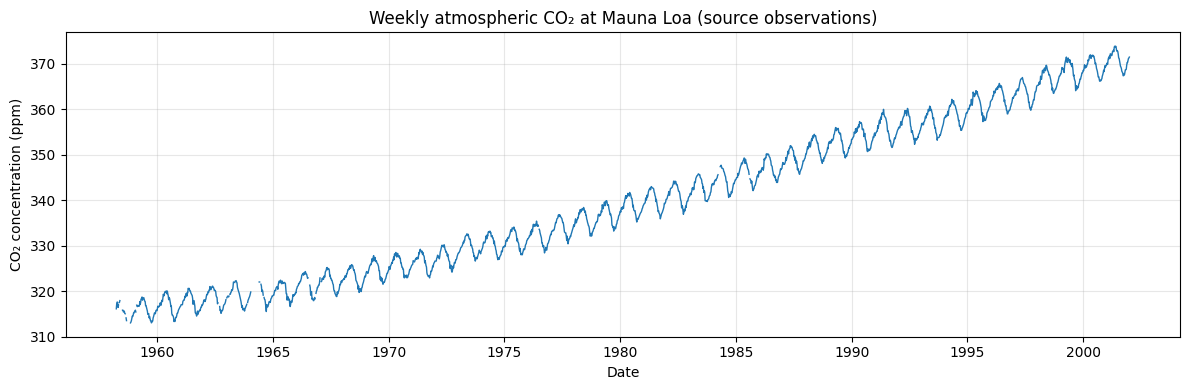

Summary statistics (excluding missing readings):


,CO2_ppm
count,2225.000000
mean,340.142247
std,17.003885
min,313.000000
25%,324.800000
50%,338.300000
75%,354.800000
max,373.900000


In [2]:
plt.figure(figsize=(12, 4))
plt.plot(raw_df["Date"], raw_df["CO2_ppm"], linewidth=1)
plt.title("Weekly atmospheric CO₂ at Mauna Loa (source observations)")
plt.xlabel("Date")
plt.ylabel("CO₂ concentration (ppm)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Summary statistics (excluding missing readings):")
display(raw_df["CO2_ppm"].describe().to_frame())

## 3. Prepare features and prediction targets

Lag features represent CO₂ values observed at the current time or before it. Rolling averages include observations only up to the current week. The target is the next week's real measurement. Month sine/cosine features represent the annual seasonal cycle.

- **Classification target:** `1` when next week's CO₂ is greater than this week's CO₂; otherwise `0`.
- **Regression target:** next week's CO₂ concentration in ppm.

Rows with any missing required feature or target are excluded. The last 20% of usable rows is reserved as the test set to preserve time order.

In [3]:
co2 = raw_df.set_index("Date")["CO2_ppm"].astype(float).sort_index()
features = pd.DataFrame(index=co2.index)

# Current and historical readings available at prediction time.
for lag in [0, 1, 2, 3, 4, 13, 26, 52]:
    features[f"co2_lag_{lag}"] = co2.shift(lag)

# Historical rolling averages through the current week (no future values).
for window in [4, 13, 52]:
    features[f"rolling_mean_{window}"] = co2.rolling(window=window).mean()

month = co2.index.month
features["month_sin"] = np.sin(2 * np.pi * month / 12)
features["month_cos"] = np.cos(2 * np.pi * month / 12)
features["time_index"] = np.arange(len(co2), dtype=float)

next_week_co2 = co2.shift(-1).rename("target_next_week")
valid_rows = features.notna().all(axis=1) & co2.notna() & next_week_co2.notna()
X = features.loc[valid_rows].copy()
y_reg = next_week_co2.loc[valid_rows].astype(float).copy()
y_cls = (next_week_co2.loc[valid_rows] > co2.loc[valid_rows]).astype(int)
y_cls.name = "increase_next_week"

print("Rows in original CSV:", len(raw_df))
print("Usable supervised examples:", len(X))
print("Number of input features:", X.shape[1])
print("Classification label counts (0 = no increase, 1 = increase):")
display(y_cls.value_counts().sort_index().rename_axis("label").to_frame("count"))

split_index = int(0.80 * len(X))
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_cls_train, y_cls_test = y_cls.iloc[:split_index], y_cls.iloc[split_index:]
y_reg_train, y_reg_test = y_reg.iloc[:split_index], y_reg.iloc[split_index:]

print("Training period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Testing period: ", X_test.index.min().date(), "to", X_test.index.max().date())
print("Train size:", len(X_train), "| Test size:", len(X_test))

Rows in original CSV: 2284
Usable supervised examples: 1755
Number of input features: 14
Classification label counts (0 = no increase, 1 = increase):


,count
label,
0,837
1,918


Training period: 1960-08-20 to 1995-04-01
Testing period:  1995-04-08 to 2001-12-22
Train size: 1404 | Test size: 351


## 4. Classification models and metrics

Two classifiers are compared: Random Forest and Logistic Regression. For each, the notebook calculates **Accuracy, Precision, Recall, ROC-AUC, and Log-Loss**. ROC-AUC is included as a useful summary of the ROC curve. The classifier with the higher test ROC-AUC is selected for the confusion-matrix display.

In [4]:
classifiers = {
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    ),
}

classification_results = {}
classification_rows = []

for model_name, model in classifiers.items():
    model.fit(X_train, y_cls_train)
    predicted_labels = model.predict(X_test)
    class_order = list(model.classes_)
    positive_class_index = class_order.index(1)
    predicted_probabilities = model.predict_proba(X_test)[:, positive_class_index]

    metrics = {
        "Accuracy": accuracy_score(y_cls_test, predicted_labels),
        "Precision": precision_score(y_cls_test, predicted_labels, zero_division=0),
        "Recall": recall_score(y_cls_test, predicted_labels, zero_division=0),
        "ROC-AUC": roc_auc_score(y_cls_test, predicted_probabilities),
        "Log-Loss": log_loss(y_cls_test, predicted_probabilities, labels=[0, 1]),
    }
    classification_results[model_name] = {
        "model": model,
        "predicted_labels": predicted_labels,
        "predicted_probabilities": predicted_probabilities,
        "metrics": metrics,
    }
    classification_rows.append({"Model": model_name, **metrics})

classification_summary = pd.DataFrame(classification_rows).set_index("Model")
print("Classification performance on the chronological test set:")
display(classification_summary.round(4))

best_classifier_name = classification_summary["ROC-AUC"].idxmax()
best_classifier = classification_results[best_classifier_name]
print("Selected for the confusion matrix:", best_classifier_name)

Classification performance on the chronological test set:


,Accuracy,Precision,Recall,ROC-AUC,Log-Loss
Model,,,,,
Random Forest Classifier,0.6838,0.7603,0.5287,0.7602,0.6354
Logistic Regression,0.7208,0.7135,0.7299,0.7797,0.5641


Selected for the confusion matrix: Logistic Regression


### 4.1 Confusion Matrix

The confusion matrix compares the true test labels with predicted labels. Class `1` means that next week's CO₂ reading is higher than the current week's reading.

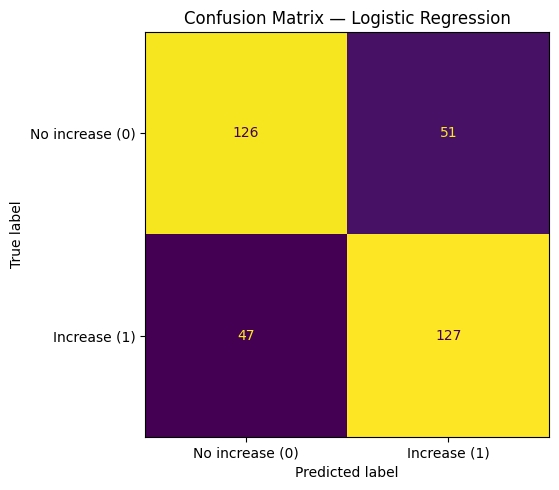

Confusion matrix (rows = actual, columns = predicted):
[[126  51]
 [ 47 127]]


In [5]:
cm = confusion_matrix(y_cls_test, best_classifier["predicted_labels"], labels=[0, 1])
display_labels = ["No increase (0)", "Increase (1)"]

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels).plot(
    ax=ax, values_format="d", colorbar=False
)
ax.set_title(f"Confusion Matrix — {best_classifier_name}")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

### 4.2 ROC Curve

The ROC curve plots the true-positive rate against the false-positive rate at different probability thresholds. The diagonal represents chance-level discrimination.

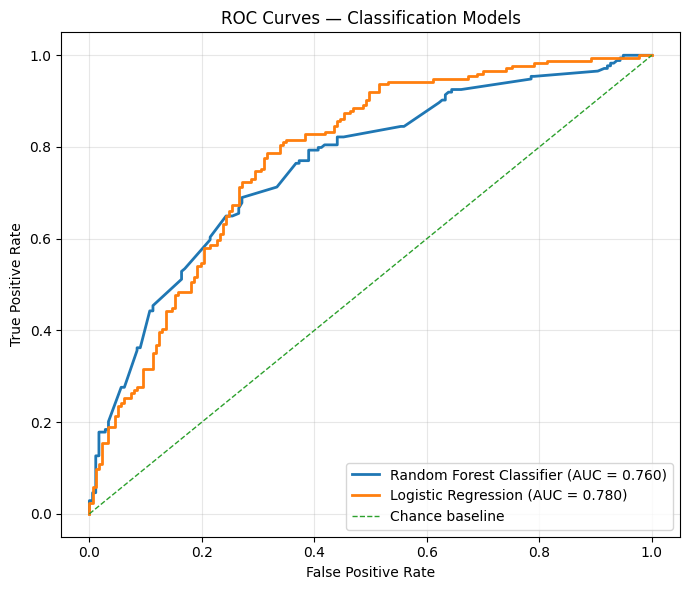

In [6]:
plt.figure(figsize=(7, 6))
for model_name, result in classification_results.items():
    fpr, tpr, _ = roc_curve(y_cls_test, result["predicted_probabilities"])
    auc = result["metrics"]["ROC-AUC"]
    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Chance baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Classification Models")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Regression models: MAD Error and Coefficient of Determination (R²)

Two regressors predict next week's CO₂ concentration. **MAD Error** is calculated as the mean of the absolute residuals, `mean(abs(actual − predicted))`, in ppm. This corresponds to the usual mean absolute error calculation. **R²** measures the fraction of test-target variance explained by predictions; a value closer to 1 indicates a better fit, while a negative value indicates performance worse than predicting the test-set mean.

In [7]:
regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
}

regression_results = {}
regression_rows = []

for model_name, model in regressors.items():
    model.fit(X_train, y_reg_train)
    predicted_values = model.predict(X_test)
    residuals = y_reg_test.to_numpy() - predicted_values
    mad_error = float(np.mean(np.abs(residuals)))
    r2 = r2_score(y_reg_test, predicted_values)

    regression_results[model_name] = {
        "model": model,
        "predictions": predicted_values,
        "residuals": residuals,
        "MAD Error (ppm)": mad_error,
        "R²": r2,
    }
    regression_rows.append({
        "Model": model_name,
        "MAD Error (ppm)": mad_error,
        "R²": r2,
    })

regression_summary = pd.DataFrame(regression_rows).set_index("Model")
print("Regression performance on the chronological test set:")
display(regression_summary.round(4))

best_regressor_name = regression_summary["MAD Error (ppm)"].idxmin()
best_regressor = regression_results[best_regressor_name]
print("Selected for regression diagnostic plots:", best_regressor_name)

Regression performance on the chronological test set:


,MAD Error (ppm),R²
Model,,
Linear Regression,0.3126,0.9890
Ridge Regression,0.3489,0.9872


Selected for regression diagnostic plots: Linear Regression


## 6. Actual vs. Predicted CO₂ Concentration

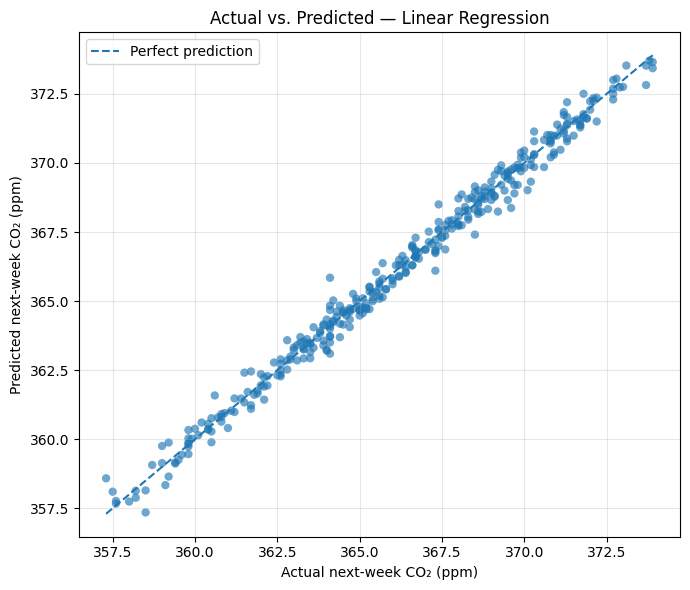

In [8]:
actual_values = y_reg_test.to_numpy()
predicted_values = best_regressor["predictions"]

plt.figure(figsize=(7, 6))
plt.scatter(actual_values, predicted_values, alpha=0.65, edgecolor="none")
limits = [min(actual_values.min(), predicted_values.min()), max(actual_values.max(), predicted_values.max())]
plt.plot(limits, limits, linestyle="--", linewidth=1.5, label="Perfect prediction")
plt.xlabel("Actual next-week CO₂ (ppm)")
plt.ylabel("Predicted next-week CO₂ (ppm)")
plt.title(f"Actual vs. Predicted — {best_regressor_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Distribution of Regression Errors

A residual is defined as `actual − predicted`. A residual above zero means the model underpredicted the CO₂ measurement; a residual below zero means it overpredicted it. The histogram shows the error distribution, while the second plot checks whether errors change systematically across the predicted range.

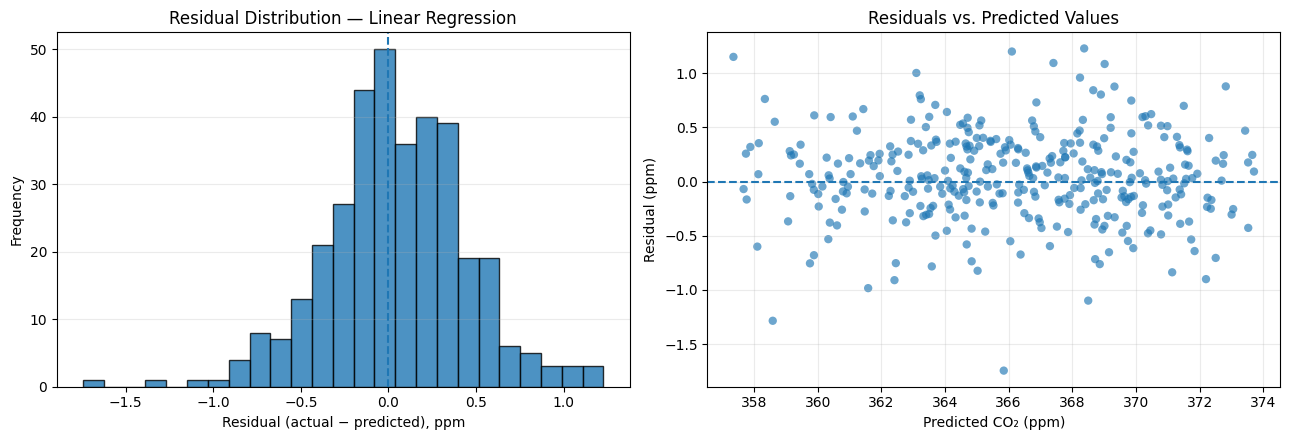

Mean absolute residual (MAD Error): 0.3126 ppm
Mean residual (bias indicator): 0.0427 ppm


In [9]:
residuals = best_regressor["residuals"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(residuals, bins=25, edgecolor="black", alpha=0.8)
axes[0].axvline(0, linestyle="--", linewidth=1.5)
axes[0].set_title(f"Residual Distribution — {best_regressor_name}")
axes[0].set_xlabel("Residual (actual − predicted), ppm")
axes[0].set_ylabel("Frequency")
axes[0].grid(True, axis="y", alpha=0.25)

axes[1].scatter(predicted_values, residuals, alpha=0.65, edgecolor="none")
axes[1].axhline(0, linestyle="--", linewidth=1.5)
axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted CO₂ (ppm)")
axes[1].set_ylabel("Residual (ppm)")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

print(f"Mean absolute residual (MAD Error): {np.mean(np.abs(residuals)):.4f} ppm")
print(f"Mean residual (bias indicator): {np.mean(residuals):.4f} ppm")

## 8. Final evaluation summary

The tables and figures above provide all requested evaluation outputs:

1. **Accuracy** — classification summary table.
2. **Confusion Matrix** — best classifier by test ROC-AUC.
3. **Precision and Recall** — classification summary table.
4. **ROC Curve** — both classifiers, with ROC-AUC in the legend.
5. **Log-Loss** — classification summary table.
6. **MAD Error** — regression summary table, in ppm.
7. **Coefficient of Determination (R²)** — regression summary table.
8. **Distribution of Errors** — residual histogram and residuals-versus-predicted plot.

The classification label is a derived target defined from real consecutive observations; it is not a supplied label in the original dataset. Interpret results as a teaching experiment on this historical series, not as a current CO₂ forecasting system.

### Dataset citation
Keeling, C. D., and T. P. Whorf (2004). *Atmospheric CO₂ concentrations derived from flask air samples at sites in the SIO network.* In *Trends: A Compendium of Data on Global Change*. Data documentation and public-domain notice: [statsmodels CO₂ dataset documentation](https://www.statsmodels.org/stable/datasets/generated/co2.html).